In [ ]:
---
## Assignment 6 — Transfer Learning with VGG16

This Colab-ready version uses MNIST digits converted to 32×32 RGB images, so it does not need a manually downloaded image-folder dataset. It loads ImageNet-pretrained VGG16 weights, freezes the convolutional base, trains a small classifier, then evaluates the test subset. VGG16 transfer learning is image classification; true object detection additionally needs bounding-box annotations and a detection model.

In [1]:
%pip install tensorflow==2.15.0 numpy==1.26.4 matplotlib h5py

Note: you may need to restart the kernel to use updated packages.


ERROR: Could not find a version that satisfies the requirement tensorflow==2.15.0 (from versions: 2.16.0rc0, 2.16.1, 2.16.2, 2.17.0rc0, 2.17.0rc1, 2.17.0, 2.17.1, 2.18.0rc0, 2.18.0rc1, 2.18.0rc2, 2.18.0, 2.18.1, 2.19.0rc0, 2.19.0, 2.19.1, 2.20.0rc0, 2.20.0, 2.21.0rc0, 2.21.0rc1, 2.21.0, 2.22.0rc0)
ERROR: No matching distribution found for tensorflow==2.15.0


58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 13s 0us/step
Epoch 1/3
141/141 ━━━━━━━━━━━━━━━━━━━━ 26s 171ms/step - accuracy: 0.6989 - loss: 1.5288 - val_accuracy: 0.8540 - val_loss: 0.5190
Epoch 2/3
141/141 ━━━━━━━━━━━━━━━━━━━━ 26s 184ms/step - accuracy: 0.8684 - loss: 0.4558 - val_accuracy: 0.8680 - val_loss: 0.4452
Epoch 3/3
141/141 ━━━━━━━━━━━━━━━━━━━━ 26s 186ms/step - accuracy: 0.9009 - loss: 0.3210 - val_accuracy: 0.8920 - val_loss: 0.3295
32/32 ━━━━━━━━━━━━━━━━━━━━ 5s 159ms/step - accuracy: 0.8920 - loss: 0.4210
Test Loss: 0.4209856688976288
Test Accuracy: 89.20000195503235 %


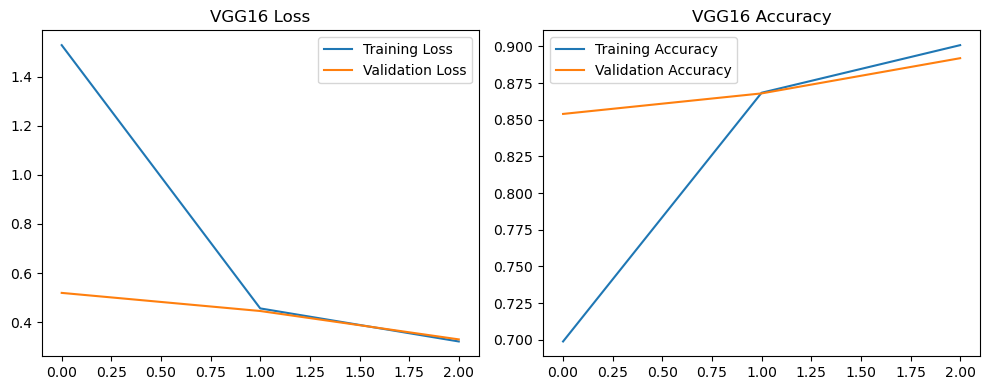

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 356ms/step


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.4850196..0.5884745].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.4850196..0.5889647].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.4850196..0.57726127].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.4850196..0.5914157].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.4850196..0.58430785].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.4850196..0.5884745].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.4850

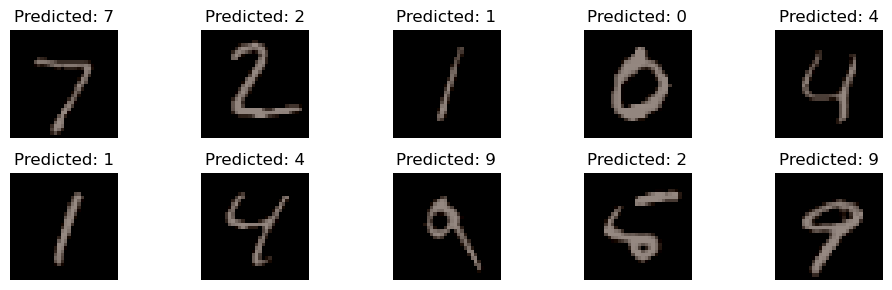

In [1]:
%matplotlib inline

import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np

# Load MNIST dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

# Use smaller subsets for faster training
x_train = x_train[:5000]
y_train = y_train[:5000]
x_test = x_test[:1000]
y_test = y_test[:1000]

# Convert grayscale images to RGB and resize to 32x32
x_train = tf.image.grayscale_to_rgb(
    tf.image.resize(x_train[..., np.newaxis], (32, 32))
)
x_test = tf.image.grayscale_to_rgb(
    tf.image.resize(x_test[..., np.newaxis], (32, 32))
)

# Preprocess for VGG16
x_train = tf.keras.applications.vgg16.preprocess_input(x_train)
x_test = tf.keras.applications.vgg16.preprocess_input(x_test)

# Load pretrained VGG16 model
base_model = tf.keras.applications.VGG16(
    weights='imagenet',
    include_top=False,
    input_shape=(32, 32, 3)
)

# Freeze convolutional layers
base_model.trainable = False

# Build classification model
model = tf.keras.Sequential([
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

# Compile model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Train model
history = model.fit(
    x_train, y_train,
    epochs=3,
    batch_size=32,
    validation_split=0.1
)

# Evaluate model
loss, accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy * 100, "%")

# Plot accuracy and loss
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('VGG16 Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('VGG16 Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

# Display sample predictions
predictions = model.predict(x_test[:10])

plt.figure(figsize=(10, 3))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i] / 255.0, cmap='gray')
    plt.title(f"Predicted: {np.argmax(predictions[i])}")
    plt.axis('off')

plt.tight_layout()
plt.show()